In [2]:
import torch
from torch import nn

In [4]:
# Download the celebA dataset 
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader

# Create a set of transforms to apply to the images
# a. Convert the images to PyTorch tensors
# b. Resize the images to 128x128
# c. Ensure that the image pixels values are in the range [0, 1]
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize((64, 64)),
    transforms.Lambda(lambda x: x.clamp(0, 1))
])

# Download the celebA dataset
train_dataset = torchvision.datasets.CelebA(
    root='../data',
    split='train',
    target_type='attr',
    transform=transform,
    download=False
)

test_dataset = torchvision.datasets.CelebA(
    root='../data',
    split='test',
    target_type='attr',
    transform=transform,
    download=False
)

# Create a DataLoader to load the dataset in batches
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, num_workers=2)

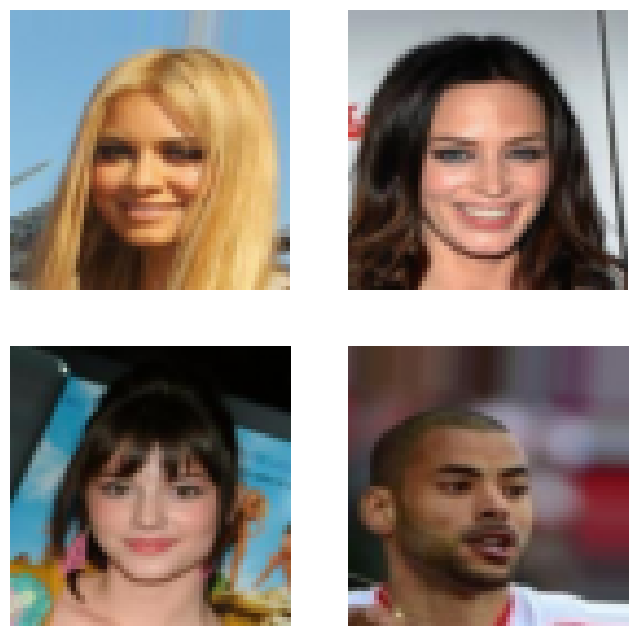

In [5]:
## Visualize some images from the dataset
import matplotlib.pyplot as plt
import numpy as np

for images, labels in train_loader:
    # Plot a few images to verify the transformations
    plt.figure(figsize=(8,8))
    for i in range(4):
        plt.subplot(2, 2, i+1)
        # Plot the RGB image
        plt.imshow(np.transpose(images[i].numpy(), (1, 2, 0)))
        # Min and max values in image tensor
        # print(torch.min(images[i]), torch.max(images[i]))
        # plt.title(f'Attributes: {labels[i].numpy()}')
        plt.axis('off')
    plt.show()
    break 

In [6]:
# Define the sampling layer for the VAE
class Sampling(nn.Module):
    def __init__(self):
        super(Sampling, self).__init__()

    def forward(self, mu, log_var):
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)
        return mu + eps * std

In [7]:
# Define the encoder of the VAE
class Encoder(nn.Module):
    def __init__(self, latent_dim):
        super(Encoder, self).__init__()
        self.latent_dim = latent_dim
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=4, stride=2, padding=1),  # 64x64 -> 32x32
            nn.BatchNorm2d(32),
            nn.LeakyReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1), # 32x32 -> 16x16
            nn.BatchNorm2d(64),
            nn.LeakyReLU(),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),# 16x16 -> 8x8
            nn.BatchNorm2d(128),
            nn.LeakyReLU(),
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),# 8x8 -> 4x4
            nn.BatchNorm2d(256),
            nn.LeakyReLU(),
            nn.Flatten()
        )
        self.fc_mu = nn.Linear(256*4*4, latent_dim)
        self.fc_log_var = nn.Linear(256*4*4, latent_dim)
        self.sampling = Sampling()

    def forward(self, x):
        x = self.conv_layers(x)
        mu = self.fc_mu(x)
        log_var = self.fc_log_var(x)
        z = self.sampling(mu, log_var)
        return z, mu, log_var

In [8]:
## Define the decoder of the VAE
class Decoder(nn.Module):
    def __init__(self, latent_dim):
        super(Decoder, self).__init__()
        self.fc = nn.Linear(latent_dim, 256*4*4)
        self.deconv_layers = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1), # 4x4 -> 8x8
            nn.BatchNorm2d(128),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),  # 8x8 -> 16x16
            nn.BatchNorm2d(64),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),   # 16x16 -> 32x32
            nn.BatchNorm2d(32),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),    # 32x32 -> 64x64
            nn.Sigmoid()  # Output pixel values between 0 and 1
        )

    def forward(self, z):
        x = self.fc(z)
        x = x.view(-1, 256, 4, 4)
        x = self.deconv_layers(x)
        return x

In [9]:
## Define the VAE model
class VAE(nn.Module):
    def __init__(self, latent_dim):
        super(VAE, self).__init__()
        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim)

    def forward(self, x):
        z, mu, log_var = self.encoder(x)
        reconstructed_x = self.decoder(z)
        return reconstructed_x, mu, log_var

In [12]:
# Train the VAE model on the celebA dataset

from torch import optim
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Initialize the VAE, optimizer, and loss function
latent_dim = 128
vae = VAE(latent_dim).to(device)

optimizer = optim.Adam(vae.parameters(), lr=1e-3)

def loss_function(reconstructed_x, x, mu, log_var, beta):
    # Reconstruction loss
    recon_loss = F.binary_cross_entropy(reconstructed_x, x, reduction='sum')
    # KL divergence
    kl_loss = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())
    return beta * recon_loss + kl_loss

num_epochs = 5
beta = 10.0  # Weight for Reconstruction vs KL divergence

vae.train()

for epoch in range(num_epochs):
    train_loss = 0
    for batch_idx, (images, _) in enumerate(train_loader):
        images = images.to(device)
        batch_size = images.size(0)
        optimizer.zero_grad()
        reconstructed_batch, mu, log_var = vae(images)
        loss = loss_function(reconstructed_batch, images, mu, log_var, beta)
        loss.backward()
        train_loss += loss.item() / batch_size
        optimizer.step()
    print(f'Epoch {epoch+1}, Loss: {train_loss}')

Epoch 1, Loss: 80579480.75724085
Epoch 2, Loss: 78306180.62004574
Epoch 3, Loss: 77985578.92844893
Epoch 4, Loss: 77812204.02782013


AcceleratorError: CUDA error: unspecified launch failure
Search for `cudaErrorLaunchFailure' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


In [39]:
## Save the model checkpoint
torch.save(vae.state_dict(), 'vae_celebA_beta_250_bce_loss_kl_sum_latent_dim_64.pt')

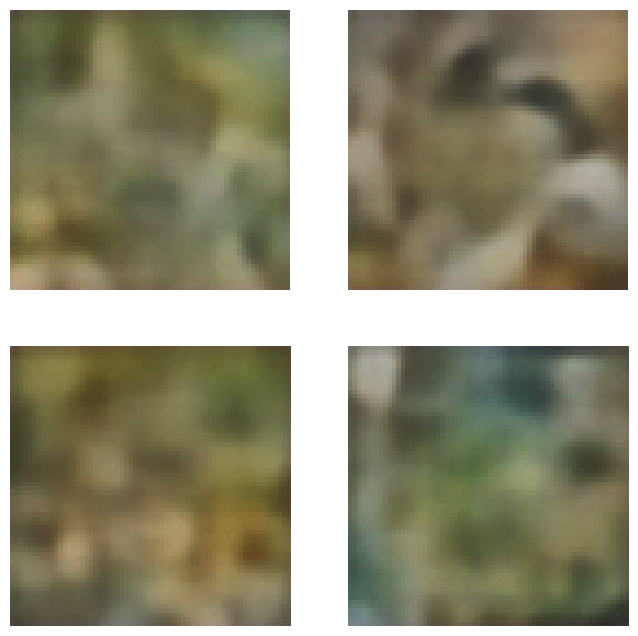

In [11]:
## Sample the latent space and generate new images
vae.eval()

with torch.no_grad():
    # Sample random latent vectors
    z = torch.randn(4, latent_dim).to(device)
    # Generate images from the sampled latent vectors
    generated_images = vae.decoder(z)
    
    # Plot the generated images
    fig, axes = plt.subplots(2, 2, figsize=(8, 8))
    for i in range(4):
        axes[i//2, i%2].imshow(np.transpose(generated_images[i].cpu().numpy(), (1, 2, 0)))
        axes[i//2, i%2].axis('off')
    plt.show()